In [14]:
import pandas as pd
from pathlib import Path
import glob
import json

import matplotlib.pyplot as plt

In [15]:
#SOURCES_TO_COMPARE = ["random_control", "hard_coded_control", "baseline", "comfort_band", "scaled_comfort", "comfort_band_hold_1h", "comfort_band_hold_2_5h"]
ALL_DAY_TEST_PHASES = ["simulation_test_setup_stuttgart", "simulation_test_setup_essen", "simulation_test_setup_garmisch", "simulation_test_setup_hamburg", "simulation_test_setup_mannheim", "simulation_test_setup_potsdam"]
ALL_MONTH_TEST_PHASES = ["simulation_november", "simulation_november_essen", "simulation_november_garmisch", "simulation_november_hamburg", "simulation_november_mannheim", "simulation_november_potsdam"]

# SOURCES_TO_COMPARE = ["random_control", "hard_coded_control", "drl_baseline", "drl_ambient_adjusted",
#                       "drl_ambient_adjusted_measured_14_days", "drl_ambient_adjusted_measured_28_days"]

# SOURCES_TO_COMPARE = ["random_control", "hard_coded_control", "drl_baseline", "drl_ambient_adjusted"]

SOURCES_TO_COMPARE = ["random_control", "hard_coded_control", "drl_ambient_adjusted", "drl_ambient_adjusted_measured_28_days"]

name_to_short_label = {
    "random_control": "Zufallsbasiert",
    "hard_coded_control": "Regelbasiert",
    "drl_baseline": "Sim-basiertes DRL\n(comfort based)",
    "drl_ambient_adjusted": "Sim-basiertes DRL\n(causality-weighted)",
    "drl_ambient_adjusted_sensitive": "Sim-basiertes DRL\n(sensitive\nadjusted reward)",
    "drl_ambient_adjusted_augmented": "Sim-basiertes DRL\n(adjusted reward,\naugmented)",
    "drl_ambient_adjusted_measured_28_days": "Messungsbasiertes DRL\n(causality-weighted)",

    "simulation_test_setup_stuttgart": "Stuttgart",
    "simulation_test_setup_essen": "Essen",
    "simulation_test_setup_garmisch": "Garmisch-P.",
    "simulation_test_setup_hamburg": "Hamburg",
    "simulation_test_setup_mannheim": "Mannheim",
    "simulation_test_setup_potsdam": "Potsdam",

    "simulation_november": "Stuttgart",
    "simulation_november_essen": "Essen",
    "simulation_november_garmisch": "Garmisch-P.",
    "simulation_november_hamburg": "Hamburg",
    "simulation_november_mannheim": "Mannheim",
    "simulation_november_potsdam": "Potsdam"
}

CONTROL_ACTIONS = {
    "all_closed": 0, # for winter night
    "all_open": 2, # for summer night
    "inside_open": 1, # for winter day (with radiation)
    "outside_open": -1 # for summer day
}

# T_HIGH = 24.0
# T_LOW = 20.0
# T_MID = (T_HIGH + T_LOW) / 2

In [16]:
def din_comfort_band(ambient_temp):
    if ambient_temp < 16:
        return (20, 22, 24)
    elif ambient_temp < 32:
        return (16 + 0.25 * ambient_temp, 18 + 0.25 * ambient_temp, 20 + 0.25 * ambient_temp)
    else:
        return (24, 26, 28)

def inside_comfort_band(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if lower <= operative_temp <= upper:
        return True
    else:
        return False

def overheating_hours(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if operative_temp > upper:
        return operative_temp - upper
    else:
        return 0

def undercooling_hours(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if operative_temp < lower:
        return lower - operative_temp
    else:
        return 0

In [17]:
phase_frames = []

for test_phase in ALL_DAY_TEST_PHASES:
    results_path = Path(fr"C:\Users\lkclu\Documents\GitHub\DTFS\results\control\{test_phase}")

    records_by_source = {}
    for source_path in results_path.iterdir():
        if not source_path.is_dir():
            continue
        records = []
        for file_path in source_path.glob("*.jsonl"):
            with open(file_path, encoding="utf-8") as file:
                records.extend(json.loads(line) for line in file if line.strip())
        if records:
            frame = pd.json_normalize(records)
            frame["source"] = source_path.name
            records_by_source[source_path.name] = frame

    if not records_by_source:
        raise FileNotFoundError(f"No JSONL result files found in {results_path}")

    phase_data = pd.concat(records_by_source.values(), ignore_index=True)
    phase_data.columns = [column.split(".")[-1] for column in phase_data.columns]

    start_date = pd.Timestamp("2024-01-01")
    phase_data["datetime"] = start_date + pd.to_timedelta(phase_data["current_time"], unit="h")
    phase_data = phase_data[phase_data["source"].isin(SOURCES_TO_COMPARE)].copy()  # .copy() avoids SettingWithCopyWarning

    phase_data[["t_low", "t_mid", "t_high"]] = phase_data["dry_bulb_temperature"].apply(
        lambda t: pd.Series(din_comfort_band(t))
    )
    phase_data["inside_comfort"] = phase_data.apply(
        lambda row: inside_comfort_band(row["dry_bulb_temperature"], row["operative_temperature"]), axis=1
    )
    phase_data["overheating"] = phase_data.apply(
        lambda row: overheating_hours(row["dry_bulb_temperature"], row["operative_temperature"]), axis=1
    )
    phase_data["undercooling"] = phase_data.apply(
        lambda row: undercooling_hours(row["dry_bulb_temperature"], row["operative_temperature"]), axis=1
    )
    phase_data["test_phase"] = name_to_short_label.get(test_phase, test_phase)

    phase_data["test_length"] = "3 repräsentative Tage"

    phase_frames.append(phase_data)

for test_phase in ALL_MONTH_TEST_PHASES:
    results_path = Path(fr"C:\Users\lkclu\Documents\GitHub\DTFS\results\control\{test_phase}")

    records_by_source = {}
    for source_path in results_path.iterdir():
        if not source_path.is_dir():
            continue
        records = []
        for file_path in source_path.glob("*.jsonl"):
            with open(file_path, encoding="utf-8") as file:
                records.extend(json.loads(line) for line in file if line.strip())
        if records:
            frame = pd.json_normalize(records)
            frame["source"] = source_path.name
            records_by_source[source_path.name] = frame

    if not records_by_source:
        raise FileNotFoundError(f"No JSONL result files found in {results_path}")

    phase_data = pd.concat(records_by_source.values(), ignore_index=True)
    phase_data.columns = [column.split(".")[-1] for column in phase_data.columns]

    start_date = pd.Timestamp("2024-01-01")
    phase_data["datetime"] = start_date + pd.to_timedelta(phase_data["current_time"], unit="h")
    phase_data = phase_data[phase_data["source"].isin(SOURCES_TO_COMPARE)].copy()  # .copy() avoids SettingWithCopyWarning

    phase_data[["t_low", "t_mid", "t_high"]] = phase_data["dry_bulb_temperature"].apply(
        lambda t: pd.Series(din_comfort_band(t))
    )
    phase_data["inside_comfort"] = phase_data.apply(
        lambda row: inside_comfort_band(row["dry_bulb_temperature"], row["operative_temperature"]), axis=1
    )
    phase_data["overheating"] = phase_data.apply(
        lambda row: overheating_hours(row["dry_bulb_temperature"], row["operative_temperature"]), axis=1
    )
    phase_data["undercooling"] = phase_data.apply(
        lambda row: undercooling_hours(row["dry_bulb_temperature"], row["operative_temperature"]), axis=1
    )
    phase_data["test_phase"] = name_to_short_label.get(test_phase, test_phase)

    phase_data["test_length"] = "1 Monat"

    phase_frames.append(phase_data)

all_data = pd.concat(phase_frames, ignore_index=True)

In [18]:
all_data.head()

,control,hour_of_day,current_time,dry_bulb_temperature,total_horizontal_radiation,operative_temperature,source,datetime,t_low,t_mid,t_high,inside_comfort,overheating,undercooling,test_phase,test_length
0,1,0.0,0.166667,12.0,0.0,18.163939,drl_ambient_adjusted,2024-01-01 00:10:00.000000001,20.0,22.0,24.0,False,0.0,1.836061,Stuttgart,3 repräsentative Tage
1,1,0.0,0.333333,12.0,0.0,18.451358,drl_ambient_adjusted,2024-01-01 00:19:59.999999998,20.0,22.0,24.0,False,0.0,1.548642,Stuttgart,3 repräsentative Tage
2,1,0.0,0.500000,12.0,0.0,18.667792,drl_ambient_adjusted,2024-01-01 00:30:00.000000000,20.0,22.0,24.0,False,0.0,1.332208,Stuttgart,3 repräsentative Tage
3,1,0.0,0.666667,12.0,0.0,18.830667,drl_ambient_adjusted,2024-01-01 00:40:00.000000001,20.0,22.0,24.0,False,0.0,1.169333,Stuttgart,3 repräsentative Tage
4,1,0.0,0.833333,12.0,0.0,18.953150,drl_ambient_adjusted,2024-01-01 00:49:59.999999998,20.0,22.0,24.0,False,0.0,1.046850,Stuttgart,3 repräsentative Tage


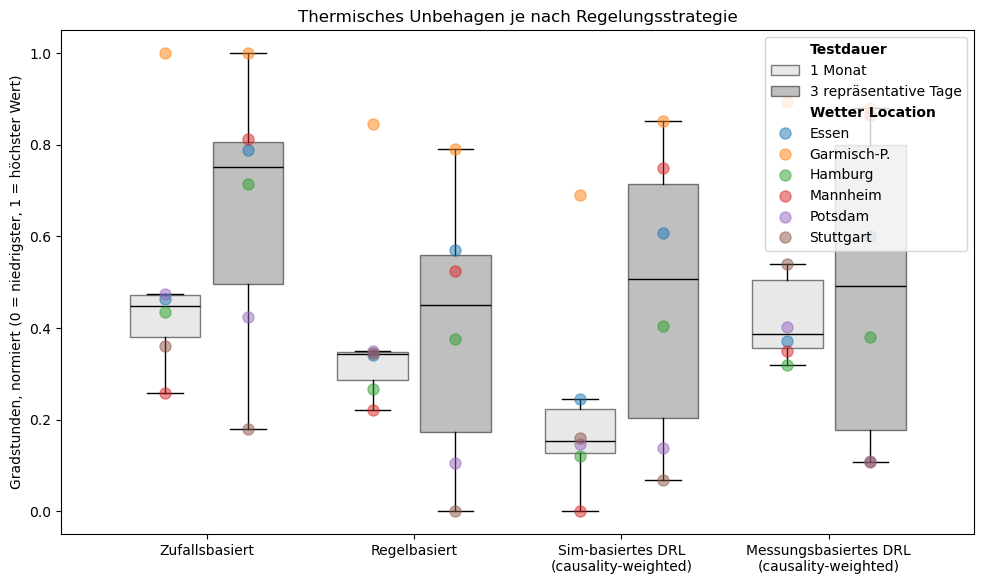

In [27]:
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# one total discomfort value (Kh) per (source, test_length, test_phase)
discomfort = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "test_length", "test_phase"])["total_discomfort"].sum() / 12
).rename("Discomfort Kh").reset_index()

# rows = (test_length, test_phase), columns = sources (order of SOURCES_TO_COMPARE, no data -> dropped)
pivot = discomfort.pivot(index=["test_length", "test_phase"], columns="source", values="Discomfort Kh")
pivot = pivot[[s for s in SOURCES_TO_COMPARE if s in pivot.columns]]

# min-max normalization within each test_length (over all sources and test phases):
# lowest value -> 0, highest value -> 1
def minmax(block):
    lo, hi = block.min().min(), block.max().max()
    return (block - lo) / (hi - lo)

pivot = pivot.groupby(level="test_length", group_keys=False).apply(minmax)

labels = [name_to_short_label.get(s, s) for s in pivot.columns]
lengths = list(pivot.index.get_level_values("test_length").unique())
phases = list(pivot.index.get_level_values("test_phase").unique())

cmap = plt.get_cmap("tab10")
phase_colors = {phase: cmap(i % 10) for i, phase in enumerate(phases)}
box_greys = ["lightgray", "gray", "dimgray", "darkgray"]  # one shade per test length

n_src, n_len = len(pivot.columns), len(lengths)
base = np.arange(1, n_src + 1)       # group centers (one group per source)
width = 0.8 / n_len                  # width of one box slot inside a group

# plot
fig, ax = plt.subplots(figsize=(10, 6))

for j, length in enumerate(lengths):
    pos = base + (j - (n_len - 1) / 2) * width
    sub = pivot.xs(length, level="test_length")          # rows = test_phase, columns = sources
    box_data = [sub[col].dropna().values for col in sub.columns]

    bp = ax.boxplot(box_data, positions=pos, widths=width * 0.85,
                    patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set_facecolor(box_greys[j % len(box_greys)])
        patch.set_alpha(0.5)
    for median in bp["medians"]:
        median.set_color("black")

    # one dot per test phase and source, colored by phase
    for phase in sub.index:
        ax.plot(pos, sub.loc[phase].values,
                color=phase_colors[phase], marker="o", markersize=8,
                linewidth=0, alpha=0.5, zorder=3)

ax.set_xticks(base)
ax.set_xticklabels(labels)
ax.set_ylabel("Gradstunden, normiert (0 = niedrigster, 1 = höchster Wert)")
ax.set_xlabel("")
ax.set_title("Thermisches Unbehagen je nach Regelungsstrategie")

# one combined legend: test length (boxes) + weather locations (dots)
length_handles = [
    Patch(facecolor=box_greys[j % len(box_greys)], alpha=0.5, edgecolor="black", label=str(length))
    for j, length in enumerate(lengths)
]
phase_handles = [
    Line2D([0], [0], marker="o", linestyle="", markersize=8, alpha=0.5,
           color=phase_colors[p], label=str(name_to_short_label.get(p, p)))
    for p in phases
]

def header(text):
    return Line2D([], [], linestyle="", label=text)   # invisible handle, acts as a heading

handles = [header("Testdauer"), *length_handles, header("Wetter Location"), *phase_handles]
leg = ax.legend(handles=handles, loc="upper right")
for t in leg.get_texts():
    if t.get_text() in ("Testdauer", "Wetter Location"):
        t.set_fontweight("bold")

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

plt.tight_layout()
plt.show()

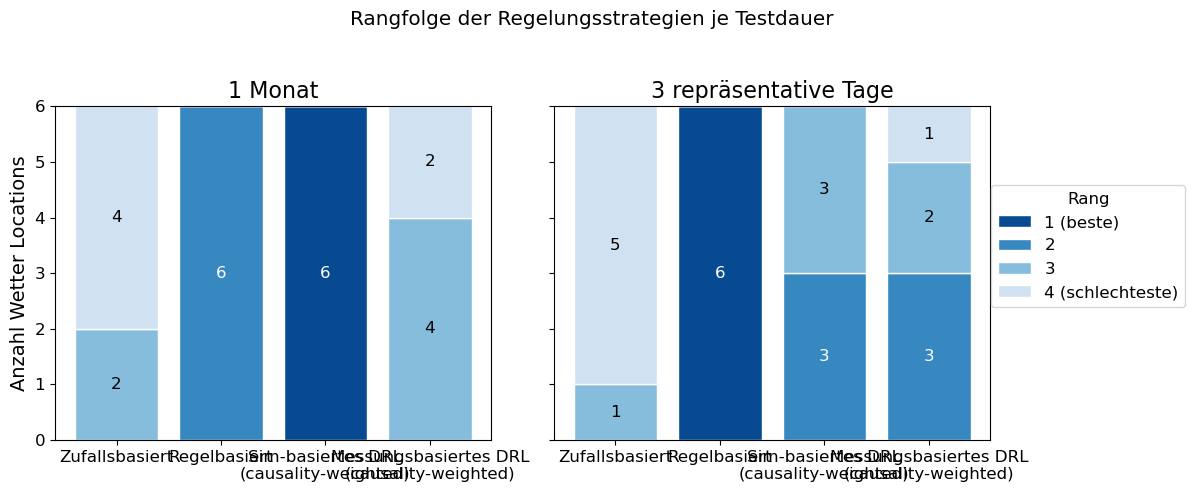

In [35]:
import numpy as np
from matplotlib.ticker import MaxNLocator

# one total discomfort value (Kh) per (source, test_length, test_phase)
discomfort = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "test_length", "test_phase"])["total_discomfort"].sum() / 12
).rename("Discomfort Kh").reset_index()

# rank 1 = lowest discomfort = best, within each (test_length, test_phase)
discomfort["rank"] = (
    discomfort.groupby(["test_length", "test_phase"])["Discomfort Kh"]
    .rank(method="min", ascending=True)
    .astype(int)
)

sources = [s for s in SOURCES_TO_COMPARE if s in discomfort["source"].unique()]
labels = [name_to_short_label.get(s, s) for s in sources]
lengths = list(discomfort["test_length"].unique())
n_src = len(sources)
ranks = list(range(1, n_src + 1))

# counts[(test_length, source)][rank] = number of weather locations where the source got that rank
counts = (
    discomfort.groupby(["test_length", "source", "rank"]).size()
    .unstack("rank", fill_value=0)
    .reindex(columns=ranks, fill_value=0)
)

# dark = best rank, light = worst rank
colors = plt.get_cmap("Blues")(np.linspace(0.9, 0.2, n_src))
rank_labels = [f"{r}" for r in ranks]
rank_labels[0] = "1 (beste)"
rank_labels[-1] = f"{n_src} (schlechteste)"

# plot
fig, axes = plt.subplots(1, len(lengths), figsize=(6 * len(lengths), 5), sharey=True, squeeze=False)
axes = axes[0]

for ax, length in zip(axes, lengths):
    c = counts.loc[length].reindex(sources, fill_value=0)
    bottom = np.zeros(n_src)
    for r, color, lab in zip(ranks, colors, rank_labels):
        vals = c[r].values
        ax.bar(range(n_src), vals, bottom=bottom, color=color, edgecolor="white", label=lab)
        for x, (v, b) in enumerate(zip(vals, bottom)):
            if v > 0:
                ax.text(x, b + v / 2, str(v), ha="center", va="center",
                        color="white" if r <= n_src / 2 else "black")
        bottom += vals
    ax.set_xticks(range(n_src))
    ax.set_xticklabels(labels)
    ax.set_title(str(length))

axes[0].set_ylabel("Anzahl Wetter Locations")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))

handles, leg_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, leg_labels, title="Rang", loc="center right")
fig.suptitle("Rangfolge der Regelungsstrategien je Testdauer")
plt.tight_layout(rect=[0, 0, 0.88, 0.95])
plt.show()

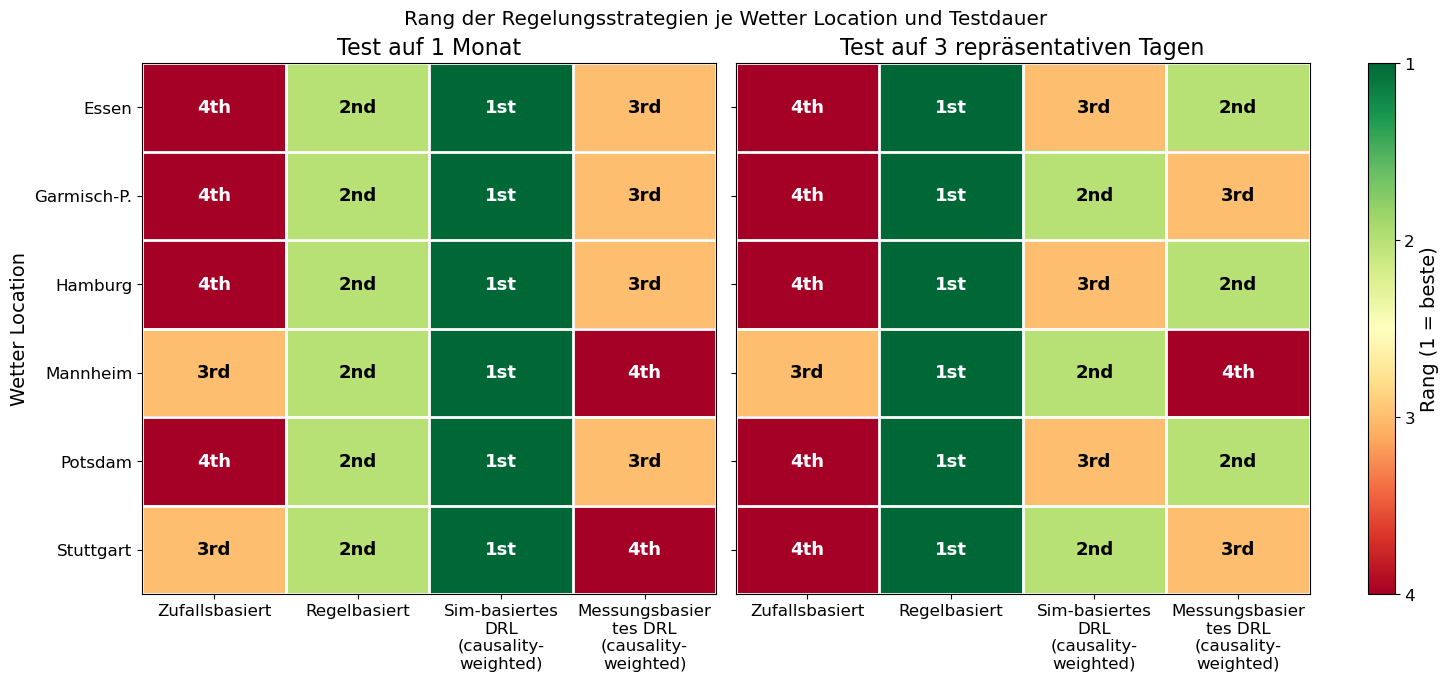

In [43]:
import textwrap
import numpy as np

def ordinal(n):
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"

# one total discomfort value (Kh) per (source, test_length, test_phase)
discomfort = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "test_length", "test_phase"])["total_discomfort"].sum() / 12
).rename("Discomfort Kh").reset_index()

# rank 1 = lowest discomfort = best, within each (test_length, test_phase)
discomfort["rank"] = (
    discomfort.groupby(["test_length", "test_phase"])["Discomfort Kh"]
    .rank(method="min", ascending=True)
    .astype(int)
)

sources = [s for s in SOURCES_TO_COMPARE if s in discomfort["source"].unique()]
xlabels = ["\n".join(textwrap.wrap(name_to_short_label.get(s, s), 14)) for s in sources]
lengths = list(discomfort["test_length"].unique())
phases = list(discomfort["test_phase"].unique())
ylabels = [name_to_short_label.get(p, p) for p in phases]
n_src, n_phase = len(sources), len(phases)
ranks = list(range(1, n_src + 1))

# rank_pivot: rows = (test_length, test_phase), columns = sources
rank_pivot = discomfort.pivot(index=["test_length", "test_phase"], columns="source", values="rank")
rank_pivot = rank_pivot[sources]

# plot: x = control strategies, y = weather locations, cell color and number = rank
fig, axes = plt.subplots(
    1, len(lengths), figsize=(max(7, 1.8 * n_src) * len(lengths), 0.7 * n_phase + 2.5),
    sharey=True, squeeze=False, constrained_layout=True,
)
axes = axes[0]

for ax, length in zip(axes, lengths):
    sub = rank_pivot.xs(length, level="test_length").reindex(phases)   # rows = weather locations
    im = ax.imshow(sub.values, cmap="RdYlGn_r", vmin=1, vmax=n_src, aspect="auto")  # green = rank 1, red = worst

    # rank inside each cell
    for i in range(n_phase):
        for j in range(n_src):
            v = sub.values[i, j]
            if np.isnan(v):
                continue
            ax.text(j, i, ordinal(int(v)), ha="center", va="center", fontsize=13, fontweight="bold",
                    color="white" if v in (1, n_src) else "black")

    ax.set_xticks(range(n_src))
    ax.set_xticklabels(xlabels)

    title_map = {"1 Monat": "Test auf 1 Monat", "3 repräsentative Tage": "Test auf 3 repräsentativen Tagen"}
    ax.set_title(title_map.get(str(length), f"Test auf {length}"))

    # white grid lines between cells
    ax.set_xticks(np.arange(-0.5, n_src, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_phase, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)

axes[0].set_yticks(range(n_phase))
axes[0].set_yticklabels(ylabels)
axes[0].set_ylabel("Wetter Location")

cb = fig.colorbar(im, ax=axes, ticks=ranks, label="Rang (1 = beste)")
cb.ax.invert_yaxis()   # rank 1 at the top of the colorbar

fig.suptitle("Rang der Regelungsstrategien je Wetter Location und Testdauer")
plt.show()

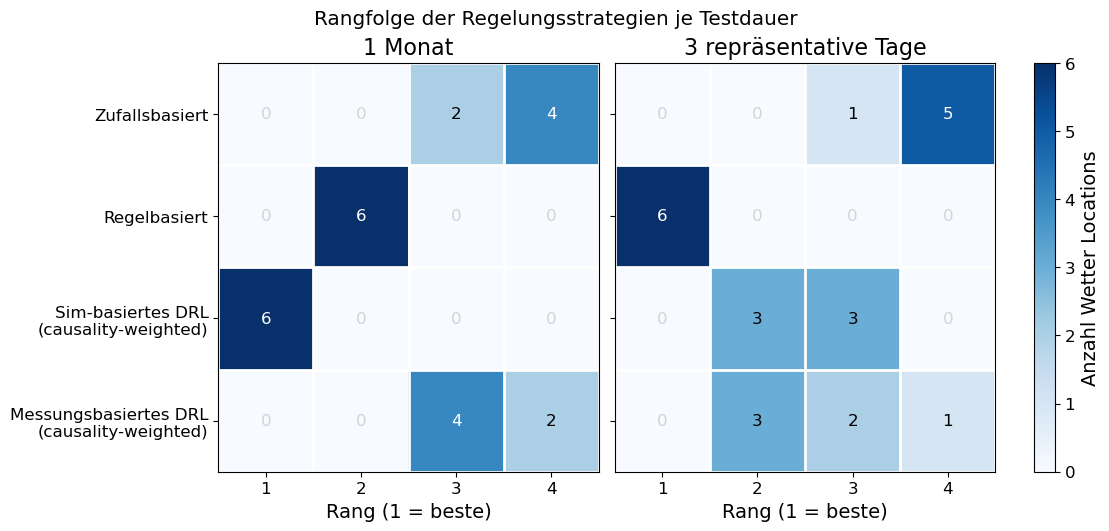

In [36]:
import numpy as np
from matplotlib.ticker import MaxNLocator

# one total discomfort value (Kh) per (source, test_length, test_phase)
discomfort = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "test_length", "test_phase"])["total_discomfort"].sum() / 12
).rename("Discomfort Kh").reset_index()

# rank 1 = lowest discomfort = best, within each (test_length, test_phase)
discomfort["rank"] = (
    discomfort.groupby(["test_length", "test_phase"])["Discomfort Kh"]
    .rank(method="min", ascending=True)
    .astype(int)
)

sources = [s for s in SOURCES_TO_COMPARE if s in discomfort["source"].unique()]
labels = [name_to_short_label.get(s, s) for s in sources]
lengths = list(discomfort["test_length"].unique())
n_src = len(sources)
ranks = list(range(1, n_src + 1))

# counts[(test_length, source)][rank] = number of weather locations where the source got that rank
counts = (
    discomfort.groupby(["test_length", "source", "rank"]).size()
    .unstack("rank", fill_value=0)
    .reindex(columns=ranks, fill_value=0)
)
vmax = counts.values.max()  # same color scale in all panels

# plot: rows = control strategies, columns = rank
fig, axes = plt.subplots(
    1, len(lengths), figsize=(5.5 * len(lengths), 0.8 * n_src + 2),
    sharey=True, squeeze=False, constrained_layout=True,
)
axes = axes[0]

for ax, length in zip(axes, lengths):
    c = counts.loc[length].reindex(sources, fill_value=0)
    im = ax.imshow(c.values, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")

    # number in every cell (zeros in gray)
    for i in range(n_src):
        for j in range(n_src):
            v = c.values[i, j]
            if v == 0:
                color = "lightgray"
            else:
                color = "white" if v > vmax / 2 else "black"
            ax.text(j, i, str(v), ha="center", va="center", color=color, fontsize=12)

    ax.set_xticks(range(n_src))
    ax.set_xticklabels(ranks)
    ax.set_xlabel("Rang (1 = beste)")
    ax.set_title(str(length))

    # white grid lines between cells
    ax.set_xticks(np.arange(-0.5, n_src, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_src, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)

axes[0].set_yticks(range(n_src))
axes[0].set_yticklabels(labels)

cb = fig.colorbar(im, ax=axes, label="Anzahl Wetter Locations")
cb.locator = MaxNLocator(integer=True)
cb.update_ticks()

fig.suptitle("Rangfolge der Regelungsstrategien je Testdauer")
plt.show()

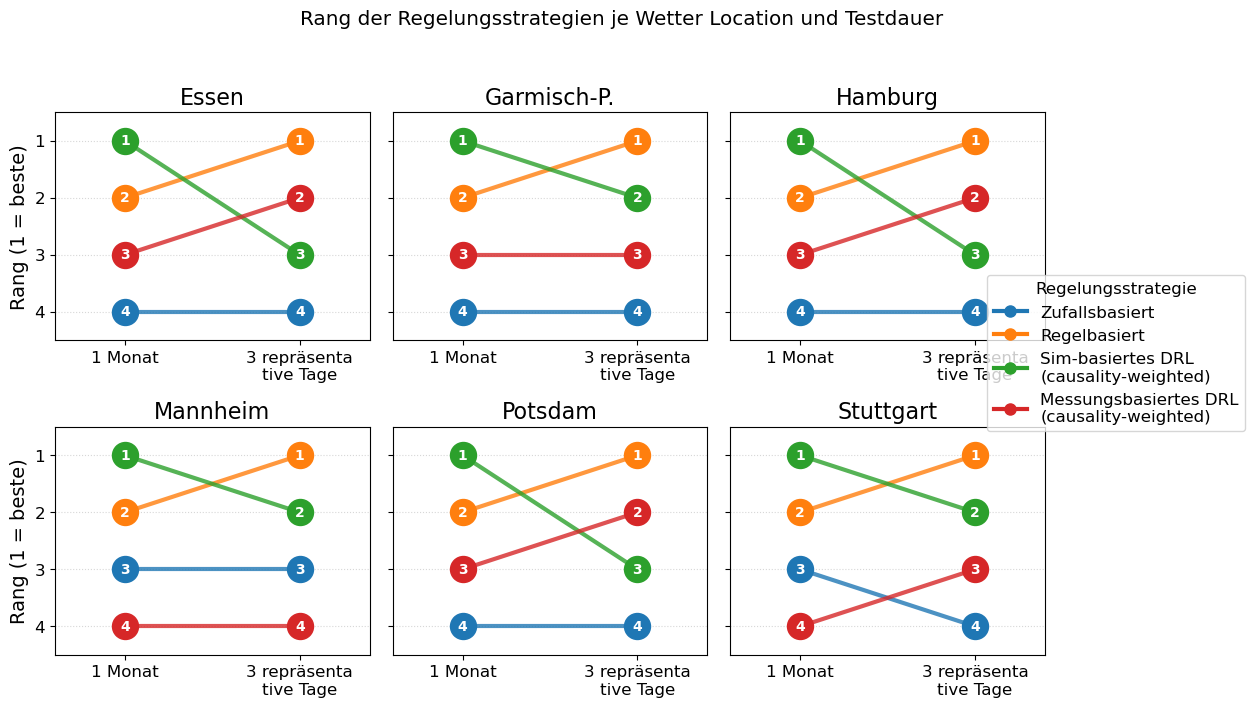

In [37]:
import math
import textwrap
import numpy as np

# one total discomfort value (Kh) per (source, test_length, test_phase)
discomfort = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "test_length", "test_phase"])["total_discomfort"].sum() / 12
).rename("Discomfort Kh").reset_index()

# rank 1 = lowest discomfort = best, within each (test_length, test_phase)
discomfort["rank"] = (
    discomfort.groupby(["test_length", "test_phase"])["Discomfort Kh"]
    .rank(method="min", ascending=True)
    .astype(int)
)

sources = [s for s in SOURCES_TO_COMPARE if s in discomfort["source"].unique()]
labels = {s: name_to_short_label.get(s, s) for s in sources}
lengths = list(discomfort["test_length"].unique())
phases = list(discomfort["test_phase"].unique())
n_src = len(sources)

# rank_pivot: rows = (test_phase, source), columns = test_length
rank_pivot = discomfort.pivot(index=["test_phase", "source"], columns="test_length", values="rank")
rank_pivot = rank_pivot[lengths]

cmap = plt.get_cmap("tab10")
src_colors = {s: cmap(i % 10) for i, s in enumerate(sources)}
x = np.arange(len(lengths))
xlabels = ["\n".join(textwrap.wrap(str(l), 12)) for l in lengths]

# one small panel per weather location
ncols = min(3, len(phases))
nrows = math.ceil(len(phases) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.6 * nrows),
                         sharey=True, squeeze=False)
axes_flat = axes.ravel()

for ax, phase in zip(axes_flat, phases):
    for s in sources:
        if (phase, s) not in rank_pivot.index:
            continue
        y = rank_pivot.loc[(phase, s)].values
        ax.plot(x, y, color=src_colors[s], linewidth=3, alpha=0.8, zorder=2)
        ax.scatter(x, y, color=src_colors[s], s=350, zorder=3)
        for xi, yi in zip(x, y):
            ax.text(xi, yi, str(int(yi)), ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold", zorder=4)

    ax.set_title(str(name_to_short_label.get(phase, phase)))
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels)
    ax.set_xlim(-0.4, len(lengths) - 0.6)
    ax.set_ylim(n_src + 0.5, 0.5)                 # rank 1 at the top
    ax.set_yticks(range(1, n_src + 1))
    ax.grid(axis="y", linestyle=":", alpha=0.5)

# hide unused panels
for ax in axes_flat[len(phases):]:
    ax.set_visible(False)

for row in axes:
    row[0].set_ylabel("Rang (1 = beste)")

# one shared legend for the control strategies
handles = [plt.Line2D([0], [0], color=src_colors[s], linewidth=3, marker="o", markersize=8, label=labels[s])
           for s in sources]
fig.legend(handles=handles, title="Regelungsstrategie", loc="center right")
fig.suptitle("Rang der Regelungsstrategien je Wetter Location und Testdauer")
plt.tight_layout(rect=[0, 0, 0.85, 0.95])
plt.show()

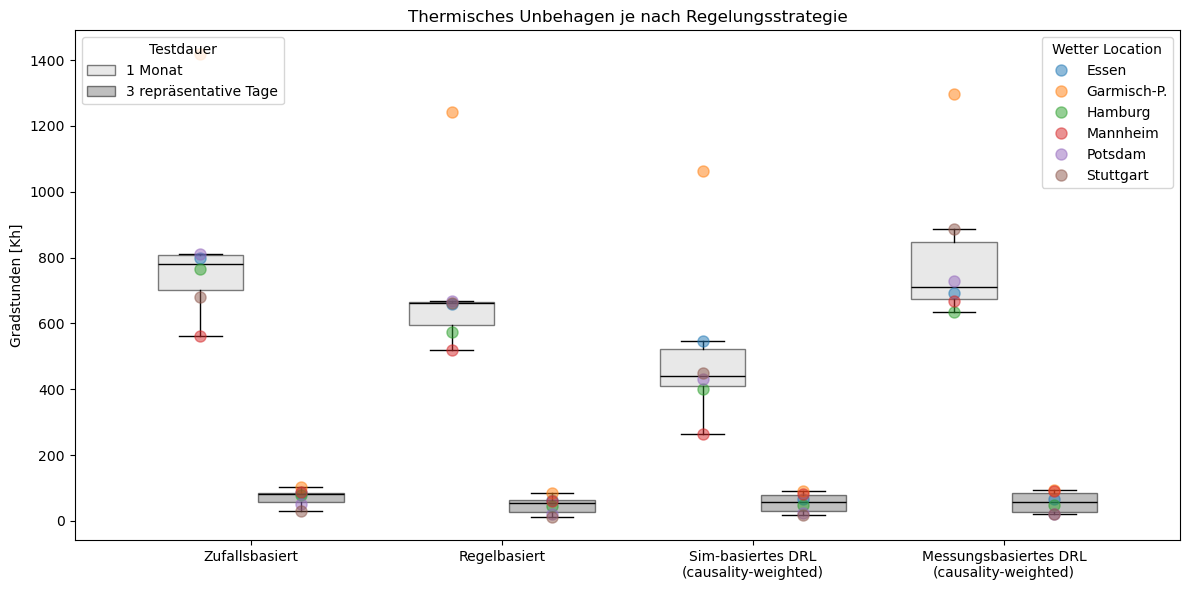

In [19]:
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# one total discomfort value (Kh) per (source, test_length, test_phase)
discomfort = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "test_length", "test_phase"])["total_discomfort"].sum() / 12
).rename("Discomfort Kh").reset_index()

# rows = (test_length, test_phase), columns = sources (order of SOURCES_TO_COMPARE, no data -> dropped)
pivot = discomfort.pivot(index=["test_length", "test_phase"], columns="source", values="Discomfort Kh")
pivot = pivot[[s for s in SOURCES_TO_COMPARE if s in pivot.columns]]

labels = [name_to_short_label.get(s, s) for s in pivot.columns]
lengths = list(pivot.index.get_level_values("test_length").unique())
phases = list(pivot.index.get_level_values("test_phase").unique())

cmap = plt.get_cmap("tab10")
phase_colors = {phase: cmap(i % 10) for i, phase in enumerate(phases)}
box_greys = ["lightgray", "gray", "dimgray", "darkgray"]  # one shade per test length

n_src, n_len = len(pivot.columns), len(lengths)
base = np.arange(1, n_src + 1)       # group centers (one group per source)
width = 0.8 / n_len                  # width of one box slot inside a group

# plot
fig, ax = plt.subplots(figsize=(12, 6))

for j, length in enumerate(lengths):
    pos = base + (j - (n_len - 1) / 2) * width
    sub = pivot.xs(length, level="test_length")          # rows = test_phase, columns = sources
    box_data = [sub[col].dropna().values for col in sub.columns]

    bp = ax.boxplot(box_data, positions=pos, widths=width * 0.85,
                    patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set_facecolor(box_greys[j % len(box_greys)])
        patch.set_alpha(0.5)
    for median in bp["medians"]:
        median.set_color("black")

    # one dot per test phase and source, colored by phase
    for phase in sub.index:
        ax.plot(pos, sub.loc[phase].values,
                color=phase_colors[phase], marker="o", markersize=8,
                linewidth=0, alpha=0.5, zorder=3)

ax.set_xticks(base)
ax.set_xticklabels(labels)
ax.set_ylabel("Gradstunden [Kh]")
ax.set_xlabel("")
ax.set_title("Thermisches Unbehagen je nach Regelungsstrategie")

# legend 1: weather locations (dots)
phase_handles = [
    Line2D([0], [0], marker="o", linestyle="", markersize=8, alpha=0.5,
           color=phase_colors[p], label=str(name_to_short_label.get(p, p)))
    for p in phases
]
leg_phase = ax.legend(handles=phase_handles, title="Wetter Location", loc="upper right")
ax.add_artist(leg_phase)

# legend 2: test length (boxes)
length_handles = [
    Patch(facecolor=box_greys[j % len(box_greys)], alpha=0.5, edgecolor="black", label=str(length))
    for j, length in enumerate(lengths)
]
ax.legend(handles=length_handles, title="Testdauer", loc="upper left")

plt.tight_layout()
plt.show()

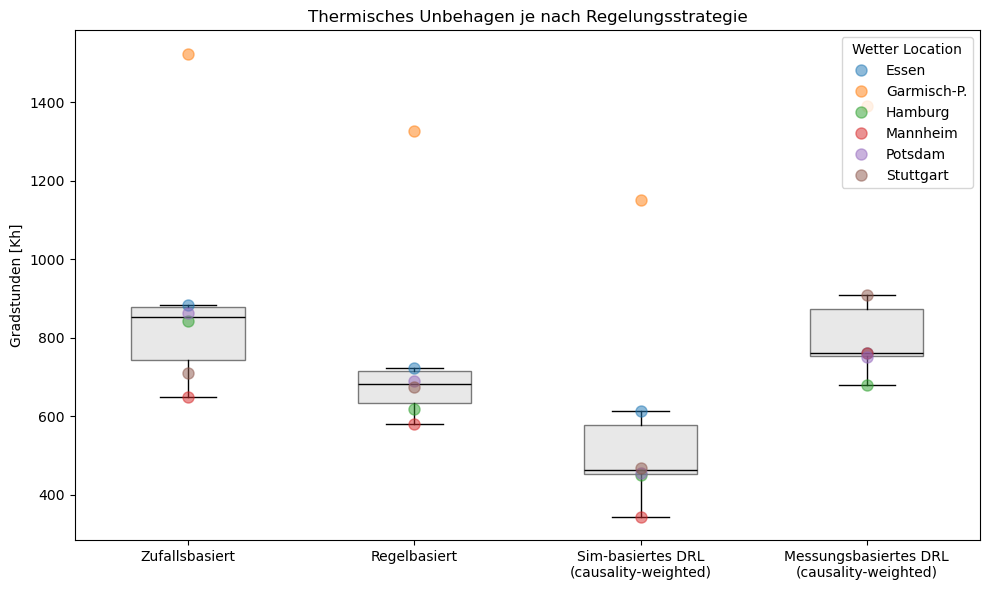

In [20]:
# one total discomfort value (Kh) per (source, test_phase)
discomfort = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "test_phase"])["total_discomfort"].sum() / 12
).rename("Discomfort Kh").reset_index()

# rows = test phases, columns = sources (in the order of SOURCES_TO_COMPARE, no data -> dropped)
pivot = discomfort.pivot(index="test_phase", columns="source", values="Discomfort Kh")
pivot = pivot[[s for s in SOURCES_TO_COMPARE if s in pivot.columns]]

labels = [name_to_short_label.get(s, s) for s in pivot.columns]
box_data = [pivot[col].dropna().values for col in pivot.columns]
x_positions = range(1, len(pivot.columns) + 1)

phases = list(pivot.index)
cmap = plt.get_cmap("tab10")
phase_colors = {phase: cmap(i % 10) for i, phase in enumerate(phases)}

# plot
fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot(box_data, patch_artist=True, widths=0.5, tick_labels=labels,  # use labels=labels for matplotlib < 3.9
                showfliers=False)
for patch in bp["boxes"]:
    patch.set_facecolor("lightgray")
    patch.set_alpha(0.5)
for median in bp["medians"]:
    median.set_color("black")

# one line + dots per test phase (single legend entry each)
for phase in phases:
    ax.plot(
        x_positions,
        pivot.loc[phase, pivot.columns].values,
        color=phase_colors[phase],
        marker="o", markersize=8, linewidth=0, alpha=0.5,
        zorder=3,
        label=str(name_to_short_label.get(phase, phase)),
    )

ax.set_ylabel("Gradstunden [Kh]")
ax.set_xlabel("")
ax.legend(title="Wetter Location", loc="upper right")
ax.set_title("Thermisches Unbehagen je nach Regelungsstrategie")
plt.tight_layout()
plt.show()